# Visual instance retrieval with SIFT and geometric verification

Given a photograph of a painting, the retrieval pipeline searches 1,611 indexed works, then checks whether the matched regions agree on their relative positions and scale. A second experiment uses local features to place a replacement image on a photographed surface. Selected figures and counts come from the recorded run.

## Local features and image pairs

OpenCV supplies the SIFT detector. Each keypoint contributes a position, scale, orientation, and 128-dimensional descriptor. The orientation bins below follow the ordering used by the painting index.

In [ ]:
from __future__ import annotations

from pathlib import Path
from urllib.parse import urlparse
import tarfile
import hashlib
import time

import cv2 as cv
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import requests
from PIL import Image
from scipy.io import loadmat
from skimage.io import imread
from skimage.transform import resize, rotate

# Matplotlib defaults
mpl.rcParams['axes.grid'] = False
mpl.rcParams['figure.dpi'] = 120

IMAGE_CACHE = Path("image_cache")
IMAGE_CACHE.mkdir(exist_ok=True)

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "VisualInstanceRetrieval/1.0"})


def _to_gray_uint8(image):
    """Convert a grayscale/RGB image to contiguous uint8 grayscale."""
    array = np.asarray(image)
    if array.ndim == 3:
        if array.shape[2] == 4:
            array = array[..., :3]
        if np.issubdtype(array.dtype, np.floating):
            scale = 255.0 if array.max(initial=0) <= 1.0 else 1.0
            rgb = np.clip(array * scale, 0, 255).astype(np.uint8)
        else:
            rgb = np.clip(array, 0, 255).astype(np.uint8)
        return cv.cvtColor(rgb, cv.COLOR_RGB2GRAY)
    if array.ndim != 2:
        raise ValueError(f'Expected a 2D or 3D image, got shape {array.shape}.')
    if np.issubdtype(array.dtype, np.floating):
        scale = 255.0 if array.max(initial=0) <= 1.0 else 1.0
        array = array * scale
    return np.ascontiguousarray(np.clip(array, 0, 255).astype(np.uint8))


def extract_sift(image, peak_thresh=0.01):
    """OpenCV-backed replacement for ``extract_sift``.

    Returns
    -------
    frames : (N, 4) float32
        Rows are ``(x, y, scale, orientation_in_radians)``.
    descriptors : (N, 128) float32
        Standard SIFT descriptors.

    ``peak_thresh`` is mapped to OpenCV's contrast threshold. The precise
    detector response scale differs from VLFeat, but increasing this value
    has the same intended effect: retaining fewer, higher-contrast features.
    """
    gray = _to_gray_uint8(image)
    threshold = max(float(peak_thresh), 1e-6)
    detector = cv.SIFT_create(contrastThreshold=threshold)
    keypoints, descriptors = detector.detectAndCompute(gray, None)

    if not keypoints:
        return np.empty((0, 4), dtype=np.float32), np.empty((0, 128), dtype=np.float32)

    # OpenCV's KeyPoint.size is a diameter. Dividing by two gives a convenient
    # scale/radius representation; ratios between scales are unchanged.
    frames = np.asarray(
        [[kp.pt[0], kp.pt[1], kp.size / 2.0, np.deg2rad(kp.angle)] for kp in keypoints],
        dtype=np.float32,
    )
    vlfeat_bins = [0, 7, 6, 5, 4, 3, 2, 1]
    descriptors = np.asarray(descriptors, dtype=np.float32)
    descriptors = descriptors.reshape(-1, 4, 4, 8)[..., vlfeat_bins].reshape(-1, 128)
    return frames, descriptors


def plotframes(frames, linewidth=1, ax=None):
    """Plot circular SIFT frames and their dominant orientations."""
    ax = plt.gca() if ax is None else ax
    frames = np.asarray(frames)
    if frames.size == 0:
        return ax
    if frames.ndim != 2 or frames.shape[1] < 4:
        raise ValueError('frames must have shape (N, 4) or wider.')

    x, y, radius, theta = (frames[:, i] for i in range(4))
    radius = np.maximum(radius, 1.0)
    circle_angles = np.linspace(0.0, 2.0 * np.pi, 25)
    circles = [
        np.column_stack((cx + r * np.cos(circle_angles), cy + r * np.sin(circle_angles)))
        for cx, cy, r in zip(x, y, radius)
    ]
    directions = [
        np.asarray([[cx, cy], [cx + r * np.cos(a), cy + r * np.sin(a)]])
        for cx, cy, r, a in zip(x, y, radius, theta)
    ]
    ax.add_collection(LineCollection(circles, linewidths=linewidth, colors='lime'))
    ax.add_collection(LineCollection(directions, linewidths=linewidth, colors='lime'))
    return ax


def pairwise_squared_l2(query, database):
    """Return the exact squared Euclidean distance matrix without a 3D tensor."""
    query = np.asarray(query, dtype=np.float32)
    database = np.asarray(database, dtype=np.float32)
    if query.ndim != 2 or database.ndim != 2 or query.shape[1] != database.shape[1]:
        raise ValueError('query and database must be 2D arrays with equal descriptor dimensions.')
    distances = (
        np.sum(query * query, axis=1, keepdims=True)
        + np.sum(database * database, axis=1)[None, :]
        - 2.0 * query @ database.T
    )
    return np.maximum(distances, 0.0)


def read_rgb_image(path_or_url, max_retries=4):
    path_or_url = str(path_or_url)

    # Handle remote images.
    if path_or_url.startswith(("http://", "https://")):
        parsed = urlparse(path_or_url)
        suffix = Path(parsed.path).suffix or ".jpg"

        cache_name = hashlib.sha256(
            path_or_url.encode("utf-8")
        ).hexdigest() + suffix

        cache_path = IMAGE_CACHE / cache_name

        # Reuse an earlier download.
        if not cache_path.exists():
            for attempt in range(max_retries):
                response = SESSION.get(
                    path_or_url,
                    timeout=30,
                )

                if response.status_code == 429:
                    retry_after = response.headers.get("Retry-After")

                    try:
                        wait_seconds = float(retry_after)
                    except (TypeError, ValueError):
                        wait_seconds = 2 ** attempt

                    print(
                        f"Rate limited; retrying in "
                        f"{wait_seconds:.1f} seconds."
                    )
                    time.sleep(wait_seconds)
                    continue

                response.raise_for_status()
                cache_path.write_bytes(response.content)
                break
            else:
                raise RuntimeError(
                    f"Could not download image after "
                    f"{max_retries} attempts:\n{path_or_url}"
                )

        image_path = cache_path

    # Handle local images.
    else:
        image_path = Path(path_or_url)

    with Image.open(image_path) as image:
        return np.asarray(image.convert("RGB"))

In [ ]:
from pathlib import Path


def download_file(urls, destination, chunk_size=1024 * 1024):
    """Download once, with HTTPS/HTTP fallback and an atomic final rename."""
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 0:
        print(f'Using cached file: {destination}')
        return destination

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + '.part')
    errors = []
    for url in urls:
        try:
            print(f'Downloading {url}')
            with requests.get(
                url,
                stream=True,
                timeout=(15, 180),
                headers={'User-Agent': 'Mozilla/5.0 (VisualInstanceRetrieval)'},
            ) as response:
                response.raise_for_status()
                with temporary.open('wb') as file:
                    for block in response.iter_content(chunk_size=chunk_size):
                        if block:
                            file.write(block)
            temporary.replace(destination)
            print(f'Saved {destination} ({destination.stat().st_size / 1e6:.1f} MB)')
            return destination
        except Exception as error:
            errors.append(f'{url}: {error}')
            temporary.unlink(missing_ok=True)

    raise RuntimeError('All download locations failed:\n' + '\n'.join(errors))


def safe_extract_tar(archive, destination):
    """Extract a tar archive while rejecting path traversal entries."""
    archive = Path(archive)
    destination = Path(destination).resolve()
    with tarfile.open(archive, mode='r:*') as tar:
        for member in tar.getmembers():
            target = (destination / member.name).resolve()
            if destination != target and destination not in target.parents:
                raise RuntimeError(f'Unsafe archive member: {member.name}')
        tar.extractall(destination, filter="data")


DATA_DIR = Path('data')
IMAGE_ARCHIVE = Path('scene-images.tar.gz')
IMAGE_URLS = [
    'https://www.di.ens.fr/willow/teaching/recvis_orig/assignment1/A1_images.tar.gz',
    'http://www.di.ens.fr/willow/teaching/recvis_orig/assignment1/A1_images.tar.gz',
]

if not DATA_DIR.exists():
    download_file(IMAGE_URLS, IMAGE_ARCHIVE)
    print('Extracting scene images...')
    safe_extract_tar(IMAGE_ARCHIVE, Path('.'))
    print('Extraction complete.')
else:
    print(f'Using existing data directory: {DATA_DIR.resolve()}')

In [ ]:
# Load an image
im1 = imread('data/oxbuild_lite/all_souls_000002.jpg')

# Let the second image be a rotated and scaled version of the first
padded = np.pad(im1, ((0, 0), (200, 200), (0, 0)), mode='constant')
im1prime = rotate(padded, angle=35, resize=True, order=1, preserve_range=True)
h, w, _ = im1prime.shape
im1prime = resize(
    im1prime,
    (int(0.7 * h), int(0.7 * w)),
    order=1,
    preserve_range=True,
    anti_aliasing=True,
).astype(np.uint8)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im1)
ax2.imshow(im1prime)
plt.show()

In [ ]:
def rgb2gray(rgb):
    """Convert RGB uint8/float images to float32 grayscale in [0, 1]."""
    gray = _to_gray_uint8(rgb)
    return gray.astype(np.float32) / 255.0

In [ ]:
# Compute SIFT features for each

[frames1, descrs1] = extract_sift(rgb2gray(im1), peak_thresh=0.01)

[frames1prime, descrs1prime] = extract_sift(rgb2gray(im1prime), peak_thresh=0.01)

f, (ax1, ax2) = plt.subplots(1, 2)
plt.sca(ax1)
plt.imshow(im1)
plotframes(frames1, linewidth=1)

plt.sca(ax2)
plt.imshow(im1prime)
plotframes(frames1prime, linewidth=1)

plt.show()

In [ ]:
# Load the second image and extract SIFT features.
im2 = imread("data/oxbuild_lite/all_souls_000015.jpg")
frames2, descrs2 = extract_sift(rgb2gray(im2))

fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.imshow(im1)
plotframes(frames1, ax=ax1)

ax2.imshow(im2)
plotframes(frames2, ax=ax2)

plt.show()

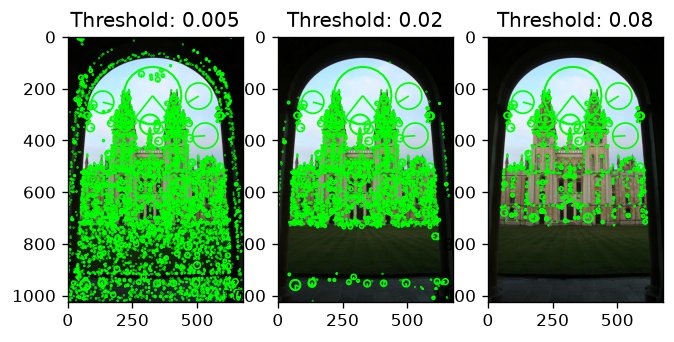

In [ ]:
peak_thresholds = [0.005, 0.02, 0.08]
fig, axes = plt.subplots(1, 3)

for ax, threshold in zip(axes, peak_thresholds):
    frames, _ = extract_sift(rgb2gray(im1), peak_thresh=threshold)
    ax.imshow(im1)
    plotframes(frames, ax=ax)
    ax.set_title(f"Threshold: {threshold}")

plt.show()

Increasing the contrast threshold leaves fewer keypoints in weakly textured areas. The remaining descriptors cost less to match. Each descriptor pools local gradient orientations, which makes matching less sensitive to illumination changes than comparing raw RGB values.

## Descriptor matches and geometric verification

The first pass assigns each descriptor its nearest neighbour. The ratio of the two smallest distances measures ambiguity. A separate RANSAC pass tests whether tentative matches agree on scale, rotation, and translation.

In [ ]:
def matching(frames1, frames2, descrs1, descrs2):
    # Number of detections in image 1.
    N_frames1 = frames1.shape[0]

    # Each row must be [index_in_image_1, index_in_image_2].
    matches = np.zeros((N_frames1, 2), dtype=np.int64)
    matches[:, 0] = np.arange(N_frames1)

    if N_frames1 == 0:
        return matches
    if descrs2.shape[0] == 0:
        raise ValueError('Image 2 has no descriptors to match against.')

    distances = pairwise_squared_l2(descrs1, descrs2)
    matches[:, 1] = np.argmin(distances, axis=1)

    return matches

In [ ]:
matches = matching(frames1, frames2, descrs1, descrs2)

In [ ]:
from matplotlib.collections import LineCollection


def plot_matches(im1, im2, frames1, frames2, matches):
    def to_rgb_float(image):
        image = np.asarray(image)

        if image.ndim == 2:
            image = np.repeat(image[..., None], 3, axis=2)

        image = image[..., :3].astype(np.float32)

        if image.size > 0 and image.max() > 1.0:
            image /= 255.0

        return np.clip(image, 0.0, 1.0)

    im1 = to_rgb_float(im1)
    im2 = to_rgb_float(im2)

    frames1 = np.asarray(frames1)
    frames2 = np.asarray(frames2)
    matches = np.asarray(matches, dtype=np.int64)

    # Display at most 4000 matches.
    # This should be enough to visualize the overall matching quality
    # without cluttering the figure.
    if len(matches) > 4000:
        selected = np.linspace(
            0,
            len(matches) - 1,
            4000,
            dtype=np.int64,
        )
        matches = matches[selected]

    height = max(im1.shape[0], im2.shape[0])
    width = im1.shape[1] + im2.shape[1]

    canvas = np.zeros((height, width, 3), dtype=np.float32)

    canvas[:im1.shape[0], :im1.shape[1]] = im1
    canvas[
        :im2.shape[0],
        im1.shape[1]:im1.shape[1] + im2.shape[1],
    ] = im2

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(canvas)

    if len(matches) > 0:
        indices1 = matches[:, 0]
        indices2 = matches[:, 1]

        points1 = frames1[indices1, :2].astype(np.float32)
        points2 = frames2[indices2, :2].astype(np.float32).copy()

        # Shift coordinates of features in the second image.
        points2[:, 0] += im1.shape[1]

        segments = np.stack((points1, points2), axis=1)

        # Reproduce Matplotlib's automatic multicolor line cycle.
        color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
        line_colors = [
            color_cycle[index % len(color_cycle)]
            for index in range(len(segments))
        ]

        line_collection = LineCollection(
            segments,
            colors=line_colors,
            linewidths=0.5,
            alpha=0.8,
        )
        ax.add_collection(line_collection)

        # Keep feature-point markers green, as in the original function.
        all_points = np.concatenate((points1, points2), axis=0)

        ax.scatter(
            all_points[:, 0],
            all_points[:, 1],
            s=5,
            c="green",
        )

    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.axis("off")

    plt.tight_layout(pad=0)
    plt.show()


plot_matches(im1, im2, frames1, frames2, matches)

In [ ]:
# Allocate the required arrays.
ratio = np.zeros(frames1.shape[0], dtype=np.float32)
matches = np.zeros((frames1.shape[0], 2), dtype=np.int64)

descrs1_float = descrs1.astype(np.float32)
descrs2_float = descrs2.astype(np.float32)

for i, descriptor in enumerate(descrs1_float):
    distances = np.linalg.norm(descrs2_float - descriptor, axis=1)
    first, second = np.argsort(distances)[:2]

    matches[i] = [i, first]
    ratio[i] = (
        distances[first] / distances[second]
        if distances[second] > 0 else 1.0
    )

In [ ]:
NN_threshold = 0.8

filtered_indices = np.flatnonzero(ratio < NN_threshold)
filtered_matches = matches[filtered_indices, :]

In [ ]:
plot_matches(im1, im2, frames1, frames2, filtered_matches)

In [ ]:
def ransac(frames1, frames2, matches, N_iters=500, dist_thresh=15):
    # Initialize.
    max_inliers = 0
    tnf = None
    best_inliers_indices = np.empty(0, dtype=np.int64)

    if len(matches) == 0:
        return tnf, best_inliers_indices

    # Run random sampling.
    for it in range(N_iters):
        # Pick a random tentative correspondence.
        match_index = np.random.randint(0, matches.shape[0])
        i = matches[match_index, 0]
        j = matches[match_index, 1]
        x_1, y_1, s_1, theta_1 = frames1[i, :]
        x_2, y_2, s_2, theta_2 = frames2[j, :]

        theta = theta_2 - theta_1
        s = s_2 / s_1
        t_x = x_2 - s * (x_1 * np.cos(theta) - y_1 * np.sin(theta))
        t_y = y_2 - s * (x_1 * np.sin(theta) + y_1 * np.cos(theta))

        # Evaluate the estimated transformation.
        X_1 = frames1[matches[:, 0], 0]
        Y_1 = frames1[matches[:, 0], 1]
        X_2 = frames2[matches[:, 1], 0]
        Y_2 = frames2[matches[:, 1], 1]

        X_1_prime = s * (
            X_1 * np.cos(theta) - Y_1 * np.sin(theta)
        ) + t_x
        Y_1_prime = s * (
            X_1 * np.sin(theta) + Y_1 * np.cos(theta)
        ) + t_y

        dist = np.sqrt(
            (X_1_prime - X_2) ** 2 +
            (Y_1_prime - Y_2) ** 2
        )

        inliers_indices = np.flatnonzero(dist < dist_thresh)
        num_of_inliers = len(inliers_indices)

        # Keep the best hypothesis.
        if num_of_inliers > max_inliers:
            max_inliers = num_of_inliers
            best_inliers_indices = inliers_indices
            tnf = [t_x, t_y, s, theta]

    return tnf, best_inliers_indices

In [ ]:
tnf, inliers_indices = ransac(frames1, frames2, matches)
filtered_matches = matches[inliers_indices, :]

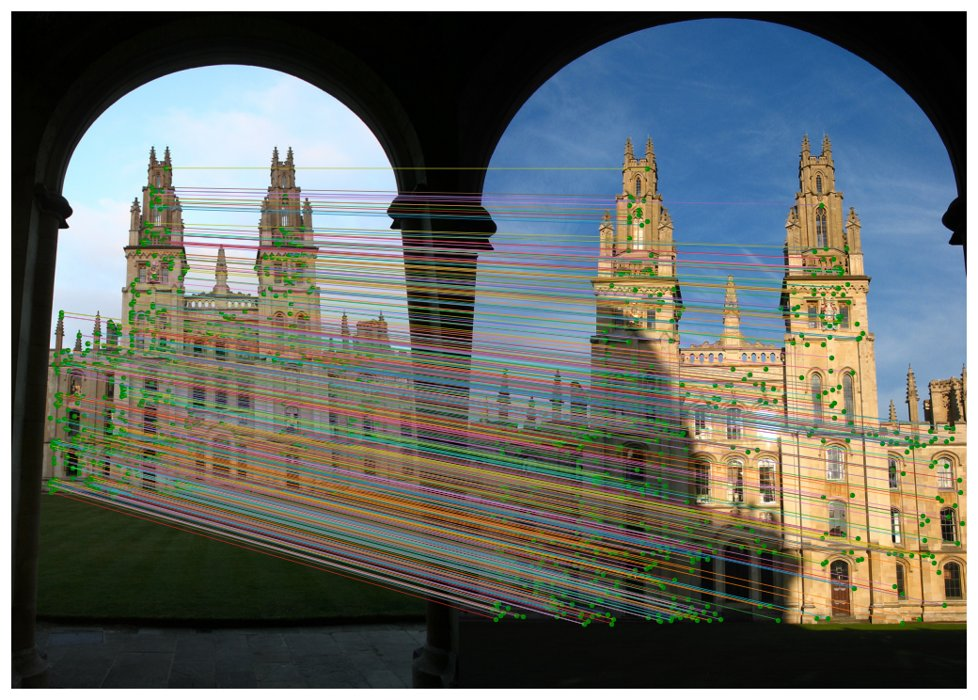

In [ ]:
plot_matches(im1, im2, frames1, frames2, filtered_matches)

## Planar image replacement

A homography maps scene coordinates to template coordinates. Each correspondence supplies two equations for a matrix defined up to scale. Four pairs in general position suffice. The implementation fits the matrix by SVD and samples the replacement with bilinear interpolation.

In [ ]:
# Load the template and the scene
template = imread('data/augmented_reality/template.png')
scene = imread('data/augmented_reality/scene.png')
h, w, _ = scene.shape
factor = h / template.shape[0]
template_width = int(round(template.shape[1] * factor))
templatexl = resize(
    template,
    (h, template_width),
    preserve_range=True,
    anti_aliasing=True,
).astype(np.uint8)

f, (ax1, ax2) = plt.subplots(1, 2)

ax1.imshow(scene)
ax2.imshow(template)
ax1.title.set_text('Scene')
ax2.title.set_text('Template')
ax1.axis('off')
ax2.axis('off')
plt.show()

In [ ]:
# Compute matches between the template and the scene

[frames_scene, descrs_scene] = extract_sift(rgb2gray(scene), peak_thresh=0.01)
[frames_template, descrs_template] = extract_sift(rgb2gray(template), peak_thresh=0.01)

matches = matching(frames_scene, frames_template, descrs_scene, descrs_template)

plot_matches(scene, templatexl, frames_scene, factor * frames_template, matches)

In [ ]:
# Filter these matches with RANSAC

tnf, inliers_indices = ransac(frames_scene, frames_template, matches)
filtered_matches = matches[inliers_indices, :]

plot_matches(scene, templatexl, frames_scene, factor * frames_template, filtered_matches)

In [ ]:
def compute_homography(frames1, frames2, matches):
    x_1 = frames1[matches[:, 0], 0]
    y_1 = frames1[matches[:, 0], 1]
    x_2 = frames2[matches[:, 1], 0]
    y_2 = frames2[matches[:, 1], 1]

    A = []
    for x1, y1, x2, y2 in zip(x_1, y_1, x_2, y_2):
        A.append([-x1, -y1, -1, 0, 0, 0, x2 * x1, x2 * y1, x2])
        A.append([0, 0, 0, -x1, -y1, -1, y2 * x1, y2 * y1, y2])

    A = np.asarray(A, dtype=np.float64)

    # Solve the homogeneous least-squares system using SVD.
    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1, :].reshape(3, 3)

    # Normalize the arbitrary homogeneous scale.
    H /= H[2, 2]

    return H

In [ ]:
H = compute_homography(frames_scene, frames_template, filtered_matches)
print(H)

[[ 1.52862548e+00 -1.27568810e-01 -4.92993079e+02]
 [-1.55417590e-01  1.65397915e+00 -1.37988705e+03]
 [-2.42549115e-04 -1.58087980e-04  1.00000000e+00]]

In [ ]:
def apply_homography(H, template, scene):
    height, width, _ = scene.shape

    # Warped template and visibility mask.
    w_template = np.zeros((height, width, 3), dtype=np.uint8)
    mask = np.zeros((height, width, 1), dtype=np.uint8)

    # For each point in the scene:
    for y in range(height):
        for x in range(width):
            # Map the scene pixel into template coordinates.
            c = np.dot(H, [x, y, 1])
            c /= c[2]
            c = c[:2]

            cx, cy = c
            if 0 <= cx < template.shape[1] - 1 and 0 <= cy < template.shape[0] - 1:
                x0, y0 = int(cx), int(cy)
                fx, fy = cx - x0, cy - y0

                w_template[y, x] = (
                    (1 - fx) * (1 - fy) * template[y0, x0]
                    + fx * (1 - fy) * template[y0, x0 + 1]
                    + (1 - fx) * fy * template[y0 + 1, x0]
                    + fx * fy * template[y0 + 1, x0 + 1]
                ).astype(np.uint8)

                mask[y, x] = 1

    # Alpha compositing.
    result = mask * w_template + (1 - mask) * scene
    return result

In [ ]:
name = "ens"  # options ["willow", "monk", "ens"]

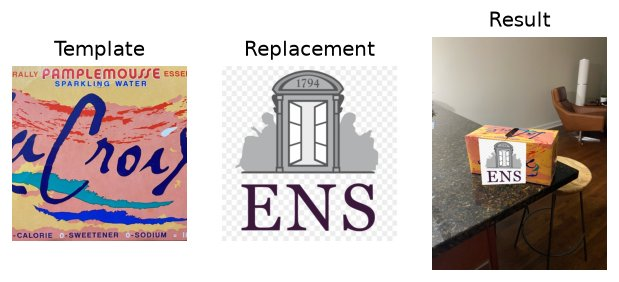

In [ ]:
# Replace the template in the scene

f, (ax1, ax2, ax3) = plt.subplots(1, 3)
replacement = imread(f'data/augmented_reality/{name}.png')
replacement = (resize(replacement, (template.shape[0], template.shape[1])) * 255).astype(np.uint8)
result = apply_homography(H, replacement, scene)

ax1.imshow(template)
ax2.imshow(replacement)
ax3.imshow(result)
ax1.title.set_text('Template')
ax2.title.set_text('Replacement')
ax3.title.set_text('Result')
ax1.axis('off')
ax2.axis('off')
ax3.axis('off')
plt.show()

## Search across the painting collection

The index contains a 10,000-word SIFT vocabulary. A KD-tree assigns query descriptors to visual words. The query histogram receives IDF weighting, a square-root transform, and L2 normalization before scoring against the indexed paintings.

In [ ]:
PAINTING_DATA = Path('paintings_imdb_SIFT_10k_preprocessed.mat')
PAINTING_URLS = [
    'https://www.di.ens.fr/willow/teaching/recvis_orig/assignment1/paintings_imdb_SIFT_10k_preprocessed.mat',
    'http://www.di.ens.fr/willow/teaching/recvis_orig/assignment1/paintings_imdb_SIFT_10k_preprocessed.mat',
]

download_file(PAINTING_URLS, PAINTING_DATA)

In [ ]:
imdb=loadmat(PAINTING_DATA)

feature_vocab = np.transpose(imdb['vocab'])
imdb_hists = imdb['index']
imdb_tfidf = imdb['idf']

imdb_url = lambda idx: imdb['images'][0][0][3][0][idx].item()

num_words = feature_vocab.shape[0]
num_paintings = imdb_hists.shape[1]

print('The vocabulary of SIFT features contains %s  visual words' % num_words)
print('The dictionary index contains %s histograms corresponding to each painting in the dataset' % num_paintings)
print('The TF-IDF vector has shape ' + str(imdb_tfidf.shape))

The vocabulary of SIFT features contains 10000  visual words
The dictionary index contains 1611 histograms corresponding to each painting in the dataset
The TF-IDF vector has shape (10000, 1)

In [ ]:
painting = imread('data/queries/mistery-painting1.jpg')

[frames, descrs] = extract_sift(rgb2gray(painting), peak_thresh=0.01)

plt.figure()
plt.imshow(painting)
plotframes(frames,linewidth=1)

In [ ]:
from sklearn.neighbors import KDTree

vocabulary_tree = KDTree(feature_vocab)
word_distances, word_indices = vocabulary_tree.query(descrs, k=1)
query_words = word_indices.ravel()

In [ ]:
query_hist = np.bincount(query_words, minlength=num_words).reshape(num_words, 1)

In [ ]:
# Process histogram: TF-IDF, Hellinger (square-root), then L2 normalization.
query_hist = query_hist * imdb_tfidf
query_hist = np.sqrt(np.maximum(query_hist, 0.0))
query_norm = np.linalg.norm(query_hist)
if query_norm <= np.finfo(float).eps:
    raise ValueError('The query produced an empty/zero visual-word histogram.')
query_hist = query_hist / query_norm

In [ ]:
scores = (query_hist.T @ imdb_hists).ravel()

In [ ]:
# sort in descending order
scores_sorted_idx = np.argsort(-scores)
scores_sorted = scores.ravel()[scores_sorted_idx]

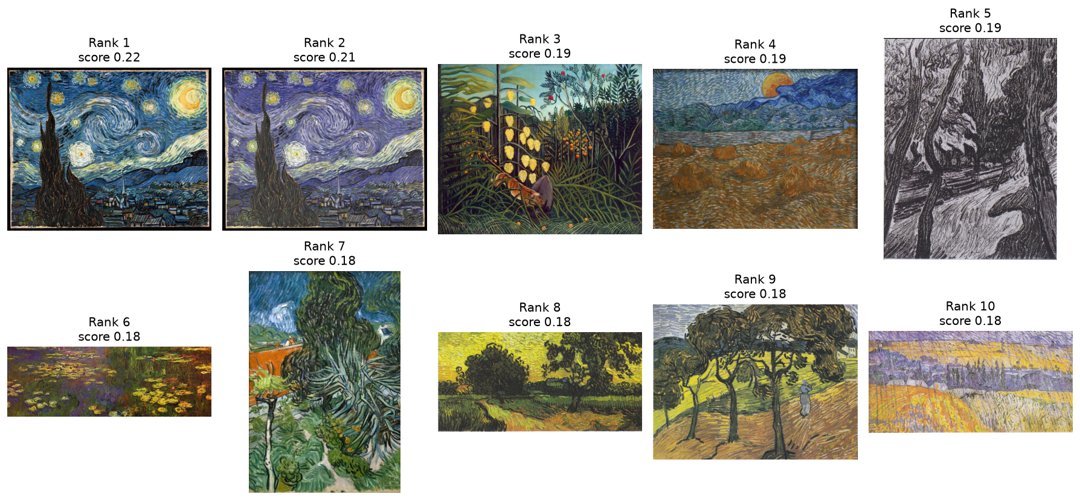

In [ ]:
# Plot the top retrieval results.
N = 10
top_N_idx = scores_sorted_idx.ravel()[:N]
top_N_scores = scores_sorted.ravel()[:N]

fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7),
)

for rank, ax in enumerate(axes.ravel()):
    image_index = int(top_N_idx[rank])
    url = imdb_url(image_index)

    try:
        image = read_rgb_image(url)

        ax.imshow(image)
        ax.set_title(
            f"Rank {rank + 1}\n"
            f"score {top_N_scores[rank]:.2f}"
        )

    except Exception as error:
        ax.text(
            0.5,
            0.5,
            "Image unavailable",
            ha="center",
            va="center",
        )
        ax.set_title(f"Rank {rank + 1}")
        print(f"Failed to load {url}: {error}")

    ax.axis("off")

    # Avoid sending requests in a rapid burst.
    time.sleep(0.25)

plt.tight_layout()
plt.show()

## Rerank the ten candidates

Repeated textures can share visual words across unrelated images. Here each pair of matching words votes for a scale and translation. The candidates are ranked again by the number of geometrically consistent pairs.

In [ ]:
RERANK_SHORTLIST = True

imdb_frames = lambda idx: imdb['images'][0][0][5][0][idx]
imdb_words = lambda idx: imdb['images'][0][0][6][0][idx]


def standardize_frames(raw_frames):
    return np.asarray(raw_frames, dtype=np.float64).T


def standardize_words(raw_words, vocabulary_size):
    return np.asarray(raw_words, dtype=np.int64).ravel() - 1


def word_matches(words1, words2, max_pairs_per_word=100):
    matches = []
    rng = np.random.default_rng(0)

    for word in np.intersect1d(words1, words2):
        indices1 = np.flatnonzero(words1 == word)
        indices2 = np.flatnonzero(words2 == word)
        pairs = np.column_stack((
            np.repeat(indices1, len(indices2)),
            np.tile(indices2, len(indices1)),
        ))
        if len(pairs) > max_pairs_per_word:
            selected = rng.choice(len(pairs), max_pairs_per_word, replace=False)
            pairs = pairs[selected]
        matches.extend(pairs)
    return np.asarray(matches, dtype=np.int64).reshape(-1, 2)


def ransac_scale_translation(
    frames1,
    frames2,
    matches,
    N_iters=300,
    dist_thresh=15,
    seed=0,
):
    best_inliers = np.empty(0, dtype=np.int64)
    if len(matches) == 0:
        return best_inliers
    rng = np.random.default_rng(seed)
    points1 = frames1[matches[:, 0], :2]
    points2 = frames2[matches[:, 1], :2]
    for _ in range(N_iters):
        i, j = matches[rng.integers(len(matches))]
        s = frames2[j, 2] / frames1[i, 2]
        translation = frames2[j, :2] - s * frames1[i, :2]
        distances = np.linalg.norm(s * points1 + translation - points2, axis=1)
        inliers = np.flatnonzero(distances < dist_thresh)
        if len(inliers) > len(best_inliers):
            best_inliers = inliers
    return best_inliers


if RERANK_SHORTLIST:
    shortlist = scores_sorted_idx.ravel()[:10]
    inlier_scores = np.zeros(len(shortlist), dtype=np.int64)

    for k, image_index in enumerate(shortlist):
        candidate_frames = standardize_frames(imdb_frames(image_index))
        candidate_words = standardize_words(imdb_words(image_index), num_words)
        tentative_matches = word_matches(query_words, candidate_words)
        inliers = ransac_scale_translation(frames, candidate_frames, tentative_matches)
        inlier_scores[k] = len(inliers)

    order = np.argsort(-inlier_scores, kind="stable")
    reranked_indices = shortlist[order]
    inlier_scores = inlier_scores[order]

    print("Original BoVW ranks:", order + 1)
    print("Inlier counts:", inlier_scores)
else:
    print("Geometric reranking disabled.")

Original BoVW ranks: [ 2  1  3  7  5 10  6  4  8  9]
Inlier counts: [69 67 14 10  8  6  5  4  4  4]

The two images of the query painting exchanged places. They had 69 and 67 inliers, followed by 14 for the strongest incorrect candidate. This is one recorded query. Measuring retrieval accuracy across paintings would require a labeled query set.